In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# 1. Temizlenmiş veriyi yükle
df = pd.read_csv(r"C:\Users\altin\OneDrive\Akademi\staj\veriler\Car_details_cleaned.csv")

# 2. X ve y olarak ayır ve Böl (Eğitim - Test)
X = df.drop(columns=["selling_price"])
y = df["selling_price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Üretim (Production) verisini temsil etmesi için test setinin bağımsız kopyalarını alıyoruz
X_prod = X_test.copy()
y_prod = y_test.copy()

# 4. SENARYO 1: Önemli bir özellikte kayma (Drift)
# Fiyat tahmini için kritik olan 'max_power' kolonunu bilinçli olarak kaydırıyoruz.
np.random.seed(42)
X_prod['max_power'] = X_prod['max_power'] + np.random.normal(40, 10, size=len(X_prod))

# 5. SENARYO 2: Fiyata etkisi görece daha az olan bir özellikte kayma
# 'max_rpm' değerlerini %20 oranında artıralım.
X_prod['max_rpm'] = X_prod['max_rpm'] * 1.2

print("Eğitim seti (Reference):", X_train.shape)
print("Üretim seti (Production):", X_prod.shape)
print("\n--- max_power Ortalamaları ---")
print(f"Eğitim: {X_train['max_power'].mean():.2f}  |  Üretim: {X_prod['max_power'].mean():.2f}")

Eğitim seti (Reference): (4300, 15)
Üretim seti (Production): (1075, 15)

--- max_power Ortalamaları ---
Eğitim: 79.48  |  Üretim: 118.80


--- max_power Kolonu KS Testi ---
P-value: 1.22034e-321
Sonuç: DRIFT TESPİT EDİLDİ! (Dağılımlar farklı)

--- max_rpm Kolonu KS Testi ---
P-value: 7.87228e-64
Sonuç: DRIFT TESPİT EDİLDİ! (Dağılımlar farklı)

--- age Kolonu KS Testi ---
P-value: 3.42836e-01
Sonuç: DRIFT YOK. (Dağılımlar benzer)



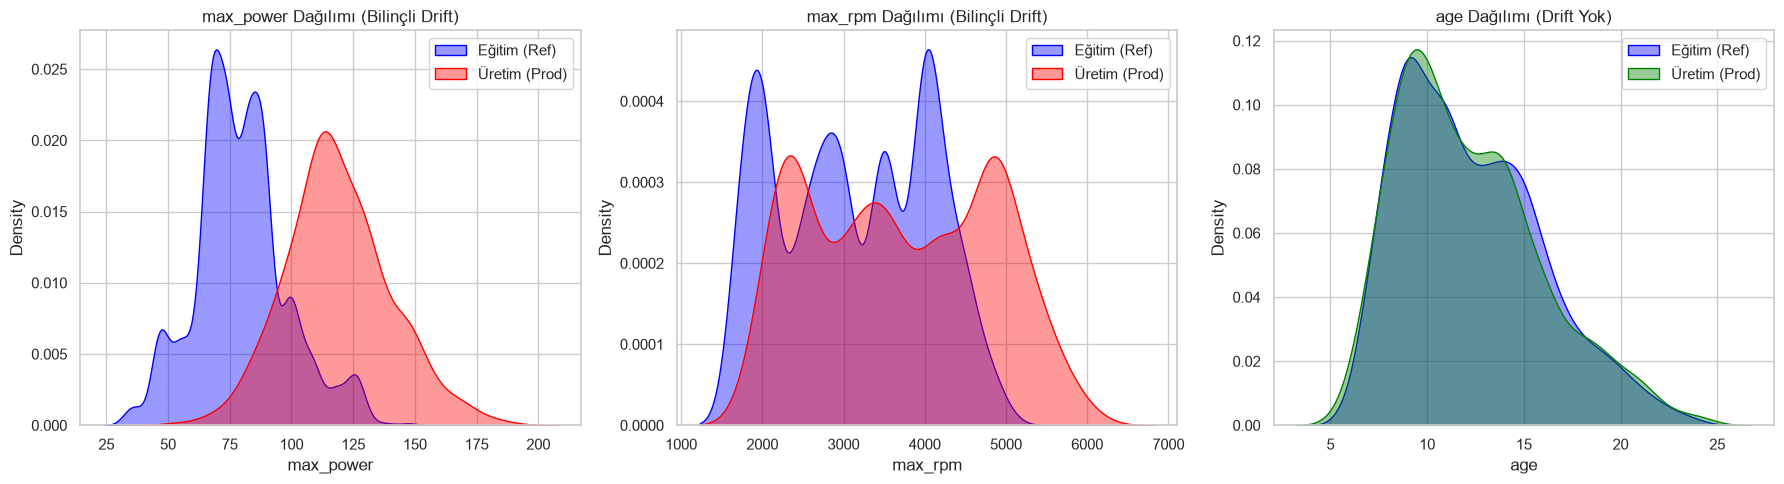

In [2]:
from scipy.stats import ks_2samp
import matplotlib.pyplot as plt
import seaborn as sns# 1. Kolmogorov-Smirnov (KS) Testi Fonksiyonu (Eksik veri kontrolü eklendi)
def check_drift(feature_name):
    # NaN değerleri analizden çıkararak KS testine sokuyoruz
    data_train = X_train[feature_name].dropna()
    data_prod = X_prod[feature_name].dropna()

    stat, p_value = ks_2samp(data_train, data_prod)

    print(f"--- {feature_name} Kolonu KS Testi ---")
    print(f"P-value: {p_value:.5e}")

    if p_value < 0.05:
        print("Sonuç: DRIFT TESPİT EDİLDİ! (Dağılımlar farklı)\n")
    else:
        print("Sonuç: DRIFT YOK. (Dağılımlar benzer)\n")

# Testleri tekrar çalıştıralım
check_drift('max_power')
check_drift('max_rpm')
check_drift('age')


# 2. Görselleştirme
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# max_power (Drift Var)
sns.kdeplot(X_train['max_power'], fill=True, label='Eğitim (Ref)', ax=axes[0], color='blue', alpha=0.4)
sns.kdeplot(X_prod['max_power'], fill=True, label='Üretim (Prod)', ax=axes[0], color='red', alpha=0.4)
axes[0].set_title('max_power Dağılımı (Bilinçli Drift)')
axes[0].legend()

# max_rpm (Drift Var)
sns.kdeplot(X_train['max_rpm'], fill=True, label='Eğitim (Ref)', ax=axes[1], color='blue', alpha=0.4)
sns.kdeplot(X_prod['max_rpm'], fill=True, label='Üretim (Prod)', ax=axes[1], color='red', alpha=0.4)
axes[1].set_title('max_rpm Dağılımı (Bilinçli Drift)')
axes[1].legend()

# age (Drift Yok)
sns.kdeplot(X_train['age'], fill=True, label='Eğitim (Ref)', ax=axes[2], color='blue', alpha=0.4)
sns.kdeplot(X_prod['age'], fill=True, label='Üretim (Prod)', ax=axes[2], color='green', alpha=0.4)
axes[2].set_title('age Dağılımı (Drift Yok)')
axes[2].legend()

plt.tight_layout()
plt.show()

In [3]:
from scipy.stats import ks_2samp

# 1. MLOps Uyumlu Drift Tespiti (D-Statistic Odaklı)
def check_drift_robust(feature_name, threshold=0.15):
    # Eksik verileri çıkarıyoruz
    data_train = X_train[feature_name].dropna()
    data_prod = X_prod[feature_name].dropna()

    # KS Testini çalıştırıyoruz
    stat, p_value = ks_2samp(data_train, data_prod)

    print(f"--- {feature_name} Kolonu Drift Kontrolü ---")
    print(f"D-Statistic (Etki Büyüklüğü): {stat:.4f} | Eşik: {threshold}")
    print(f"P-value: {p_value:.5e} (Sadece referans)")

    # Kararı P-Value'ya göre değil, D-Statistic'e göre veriyoruz!
    if stat > threshold:
        print("🔴 ALARM: ANLAMLI DRIFT TESPİT EDİLDİ! (Modelin performansı risk altında olabilir)\n")
    else:
        print("🟢 GÜVENLİ: DRIFT YOK VEYA ÖNEMSİZ. (Fark tolere edilebilir seviyede)\n")

# Testleri tekrar çalıştıralım
check_drift_robust('max_power', threshold=0.15)
check_drift_robust('max_rpm', threshold=0.15)
check_drift_robust('age', threshold=0.15)

--- max_power Kolonu Drift Kontrolü ---
D-Statistic (Etki Büyüklüğü): 0.7330 | Eşik: 0.15
P-value: 1.22034e-321 (Sadece referans)
🔴 ALARM: ANLAMLI DRIFT TESPİT EDİLDİ! (Modelin performansı risk altında olabilir)

--- max_rpm Kolonu Drift Kontrolü ---
D-Statistic (Etki Büyüklüğü): 0.2949 | Eşik: 0.15
P-value: 7.87228e-64 (Sadece referans)
🔴 ALARM: ANLAMLI DRIFT TESPİT EDİLDİ! (Modelin performansı risk altında olabilir)

--- age Kolonu Drift Kontrolü ---
D-Statistic (Etki Büyüklüğü): 0.0319 | Eşik: 0.15
P-value: 3.42836e-01 (Sadece referans)
🟢 GÜVENLİ: DRIFT YOK VEYA ÖNEMSİZ. (Fark tolere edilebilir seviyede)



In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from category_encoders import TargetEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# 1. Kolonları Tanımlama
num_cols = ['age', 'km_driven', 'mileage', 'engine', 'max_power', 'torque_nm', 'max_rpm']
low_card_cat_cols = ['fuel', 'seller_type', 'transmission', 'owner', 'brand', 'seats']
high_card_cat_cols = ['model', 'trim']

# 2. MLOps Standartlarında Dönüştürücü (Eksik verileri Pipeline içinde dolduruyoruz)
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

low_cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

high_cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', TargetEncoder())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('low_cat', low_cat_transformer, low_card_cat_cols),
        ('high_cat', high_cat_transformer, high_card_cat_cols)
    ],
    remainder='passthrough'
)

# 3. Modeli Kurma
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

# 4. Modeli SADECE X_train (Reference) ile Eğitiyoruz
model_pipeline.fit(X_train, y_train)

# 5. Tahminleri Alıp Performansı Ölçüyoruz
# --- Senaryo A: Drift OLMAYAN Orijinal Test Verisi ---
preds_normal = model_pipeline.predict(X_test)
r2_normal = r2_score(y_test, preds_normal)
mae_normal = mean_absolute_error(y_test, preds_normal)

# --- Senaryo B: Drift OLAN Production Verisi ---
preds_prod = model_pipeline.predict(X_prod)
r2_prod = r2_score(y_prod, preds_prod)
mae_prod = mean_absolute_error(y_prod, preds_prod)

print("--- MODEL PERFORMANSI KARŞILAŞTIRMASI ---")
print(f"Normal Test Seti (Drift Yok)  -> R2: {r2_normal:.4f} | MAE: {mae_normal:,.2f}")
print(f"Production Seti (Drift Var)   -> R2: {r2_prod:.4f} | MAE: {mae_prod:,.2f}")

--- MODEL PERFORMANSI KARŞILAŞTIRMASI ---
Normal Test Seti (Drift Yok)  -> R2: 0.8092 | MAE: 72,844.16
Production Seti (Drift Var)   -> R2: 0.6834 | MAE: 104,486.69


C:\Users\altin\PyCharmMiscProject\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\altin\PyCharmMiscProject\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [13]:
import pandas as pd
import numpy as np
from scipy.stats import ks_2samp
from sklearn.metrics import mean_absolute_error, r2_score

# Test edilecek ortalama kayma miktarları
drift_magnitudes = [*range(0,50)]
results = []

for drift in drift_magnitudes:
    # 1. Taze bir üretim verisi kopyası al
    X_prod_sim = X_test.copy()
    y_prod_sim = y_test.copy()

    # 2. Kaymayı (drift) uygula
    np.random.seed(42)
    if drift > 0:
        X_prod_sim['max_power'] = X_prod_sim['max_power'] + np.random.normal(drift, 10, size=len(X_prod_sim))

    # 3. KS Testi D-Statistic Hesaplama
    stat, p_val = ks_2samp(X_test['max_power'].dropna(), X_prod_sim['max_power'].dropna())

    # 4. Model Performansını Ölçme
    preds = model_pipeline.predict(X_prod_sim)
    r2 = r2_score(y_prod_sim, preds)
    mae = mean_absolute_error(y_prod_sim, preds)

    # 5. Sonuçları Kaydet
    results.append({
        'Drift_Miktari': f"+{drift}",
        'D_Statistic': stat,
        'Drift_Var_Mi_(Esik_0.15)': "Evet" if stat > 0.15 else "Hayir",
        'R2_Skoru': r2,
        'MAE': mae
    })

# Raporu Görüntüle
df_report = pd.DataFrame(results)
display(df_report)

C:\Users\altin\PyCharmMiscProject\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\altin\PyCharmMiscProject\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\altin\PyCharmMiscProject\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\altin\PyCharmMiscProject\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all 

,Drift_Miktari,D_Statistic,Drift_Var_Mi_(Esik_0.15),R2_Skoru,MAE
0,+0,0.000000,Hayir,0.809186,72844.158200
1,+1,0.116845,Hayir,0.802975,74999.088020
2,+2,0.130477,Hayir,0.802656,75291.116745
3,+3,0.151899,Evet,0.802160,75618.067047
4,+4,0.170399,Evet,0.801487,75978.246187
5,+5,0.185979,Evet,0.800638,76372.847402
6,+6,0.194742,Evet,0.799612,76807.220674
7,+7,0.210321,Evet,0.798409,77283.325883
8,+8,0.225901,Evet,0.797029,77792.095537
9,+9,0.248296,Evet,0.795473,78349.790649


In [ ]:
#6 dan 7 ye geçerken ciddi fark oluşuyor. İşimize göre ondan önceki kaymalar göz ardı edilebilir.

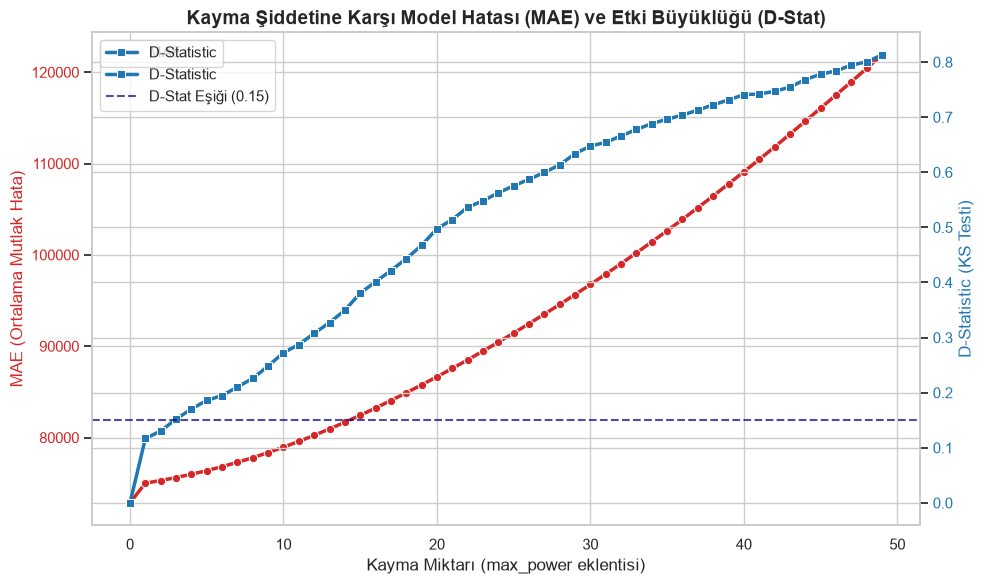

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# "Drift_Miktari" kolonundaki "+10" gibi string ifadeleri çizim için sayısala çeviriyoruz
df_report['Drift_Num'] = df_report['Drift_Miktari'].str.replace('+', '').astype(int)

# Grafik stilini ayarlayalım
sns.set_theme(style="whitegrid")
fig, ax1 = plt.subplots(figsize=(10, 6))

# 1. Y Ekseni (Sol): MAE (Model Hatası)
color_mae = 'tab:red'
ax1.set_xlabel('Kayma Miktarı (max_power eklentisi)', fontsize=12)
ax1.set_ylabel('MAE (Ortalama Mutlak Hata)', color=color_mae, fontsize=12)
sns.lineplot(data=df_report, x='Drift_Num', y='MAE', marker='o', color=color_mae, ax=ax1, linewidth=2.5, label='MAE')
ax1.tick_params(axis='y', labelcolor=color_mae)

# 2. Y Ekseni (Sağ): D-Statistic (Drift Büyüklüğü)
ax2 = ax1.twinx()
color_dstat = 'tab:blue'
ax2.set_ylabel('D-Statistic (KS Testi)', color=color_dstat, fontsize=12)
sns.lineplot(data=df_report, x='Drift_Num', y='D_Statistic', marker='s', color=color_dstat, ax=ax2, linewidth=2.5, label='D-Statistic')
ax2.tick_params(axis='y', labelcolor=color_dstat)

# D-Statistic için 0.15 kritik eşiğini yatay kesik çizgi olarak ekleyelim
ax2.axhline(0.15, ls='--', color='navy', alpha=0.7, label='D-Stat Eşiği (0.15)')

# Lejantları düzenleme
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left')

# Başlık ve yerleşim
plt.title('Kayma Şiddetine Karşı Model Hatası (MAE) ve Etki Büyüklüğü (D-Stat)', fontsize=14, fontweight='bold')
fig.tight_layout()
plt.show()